# Fine-tuning an encoder (BERT-style) for sentiment

In [1]:
%pip install -q -U transformers datasets accelerate scikit-learn pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import time, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, set_seed, pipeline)
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

set_seed(42)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
BF16 = torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8   # False on T4 -> fp16

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Tesla T4


## Data

**Rotten Tomatoes** (≈8.5k train / 1k validation / 1k test)

In [3]:
ds = load_dataset("cornell-movie-review-data/rotten_tomatoes")
id2label = {0: "negative", 1: "positive"}
label2id = {v: k for k, v in id2label.items()}
print(ds)
for split in ds:
    print(split, pd.Series(ds[split]["label"]).map(id2label).value_counts().to_dict())

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

test.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
})
train {'positive': 4265, 'negative': 4265}
validation {'positive': 533, 'negative': 533}
test {'positive': 533, 'negative': 533}


## Data quality checks

Some common sanity checks to avoid big issues with misleading model performance.

In [4]:
df = {split: ds[split].to_pandas() for split in ds}
for split, d in df.items():
    n_words = d.text.str.split().str.len()
    print(f"{split:>10}: {len(d):5d} rows | positive share {d.label.mean():.2f} | "
          f"words median {n_words.median():.0f}, min {n_words.min()}, max {n_words.max()} | "
          f"empty {(d.text.str.strip() == '').sum()}")

all_df = pd.concat([d.assign(split=s) for s, d in df.items()])
dups = all_df[all_df.duplicated("text", keep=False)]
conflicting = (dups.groupby("text").label.nunique() > 1).sum()
print(f"\nduplicate texts: {dups.text.nunique()} (with conflicting labels: {conflicting})")

for a, b in [("train", "test"), ("train", "validation"), ("validation", "test")]:
    leak = set(df[a].text) & set(df[b].text)
    print(f"exact overlap {a} ∩ {b}: {len(leak)}")

     train:  8530 rows | positive share 0.50 | words median 20, min 1, max 59 | empty 0
validation:  1066 rows | positive share 0.50 | words median 21, min 1, max 54 | empty 0
      test:  1066 rows | positive share 0.50 | words median 20, min 3, max 52 | empty 0

duplicate texts: 0 (with conflicting labels: 0)
exact overlap train ∩ test: 0
exact overlap train ∩ validation: 0
exact overlap validation ∩ test: 0


In [5]:
# Always READ a random sample — statistics don't show everything
pd.set_option("display.max_colwidth", 200)
df["train"].sample(10, random_state=0)

,text,label
725,the plot is so amusingly contrived and outlandish in its coincidences that no one could ever mistake it for anything resembling reality,1
1589,steven spielberg brings us another masterpiece,1
8504,this ludicrous film is predictable at every turn .,0
233,denis and co-writer michele petin's impeccable screenplay penetrates with a rawness that that is both unflinching and tantalizing . lead provocatuers testud and parmentier give superlative perform...,1
8208,"lush and beautifully photographed ( somebody suggested the stills might make a nice coffee table book ) , but ultimately you'll leave the theater wondering why these people mattered .",0
5731,"occasionally interesting but essentially unpersuasive , a footnote to a still evolving story .",0
4257,"constantly touching , surprisingly funny , semi-surrealist exploration of the creative act .",1
187,those outside show business will enjoy a close look at people they don't really want to know .,1
6404,"it's the kind of movie that ends up festooning u . s . art house screens for no reason other than the fact that it's in french ( well , mostly ) with english subtitles and is magically 'significan...",0
2990,a frustrating yet deeply watchable melodrama that makes you think it's a tougher picture than it is .,1


## 3 · Choose an encoder and tokenise

| Model | Use when |
|---|---|
| `answerdotai/ModernBERT-base` | English, modern & fast (default here) |
| `FacebookAI/xlm-roberta-base` | Multilingual incl. Slovenian |
| `EMBEDDIA/sloberta` | Slovenian |

Look at the token-length distribution before choosing `max_length`.

token length percentiles 50/95/99/max: [27. 47. 56.] 70


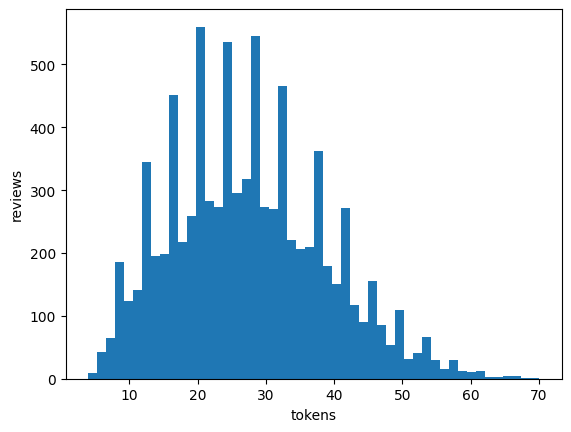

In [14]:
MODEL = "answerdotai/ModernBERT-base"
tok = AutoTokenizer.from_pretrained(MODEL)

lengths = [len(ids) for ids in tok([_s for _s in ds["train"]["text"]])["input_ids"]]
print("token length percentiles 50/95/99/max:", np.percentile(lengths, [50, 95, 99]).round(), max(lengths))
plt.hist(lengths, bins=50); plt.xlabel("tokens"); plt.ylabel("reviews"); plt.show()

In [15]:
MAX_LEN = 56      # covers > 99% of reviews here; adjust for your data

def encode(batch):
    return tok(batch["text"], truncation=True, max_length=MAX_LEN)

ds_tok = ds.map(encode, batched=True, remove_columns=["text"])
collator = DataCollatorWithPadding(tok)      # dynamic padding per batch
ds_tok

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 1066
    })
})

### Baseline: frozen encoder + logistic regression

Fine-tuning = logistic regression on **learned** features. Here we keep the encoder **frozen**, take its (mean-pooled) token vectors as features, and train only a logistic regression on top. It runs in a minute and shows how much full fine-tuning adds.

In [19]:
def metrics_from(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro")}

In [24]:
y_test = np.array(ds["test"]["label"])
results = {}

In [25]:
from transformers import AutoModel
from sklearn.linear_model import LogisticRegression

frozen = AutoModel.from_pretrained(MODEL).to("cuda").eval()

@torch.no_grad()
def embed(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        b = tok(texts[i:i+bs], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to("cuda")
        h = frozen(**b).last_hidden_state
        m = b["attention_mask"].unsqueeze(-1)
        out.append(((h * m).sum(1) / m.sum(1)).float().cpu().numpy())     # mean pooling
    return np.concatenate(out)

X_train, X_test = embed(ds["train"]["text"]), embed(ds["test"]["text"])
probe = LogisticRegression(max_iter=3000).fit(X_train, ds["train"]["label"])
results["frozen encoder + logistic regression"] = metrics_from(y_test, probe.predict(X_test))
del frozen; torch.cuda.empty_cache()
pd.DataFrame(results).T.round(3)

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,accuracy,macro_f1
frozen encoder + logistic regression,0.763,0.763


## Fine-tune

In [28]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return metrics_from(labels, preds)

def make_args(out, epochs=3, lr=3e-5, **kw):
    return TrainingArguments(
        output_dir=out, learning_rate=lr, num_train_epochs=epochs,
        per_device_train_batch_size=32, per_device_eval_batch_size=64,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="macro_f1",
        bf16=BF16, fp16=not BF16 and torch.cuda.is_available(),
        logging_steps=50, report_to="none", seed=42, **kw)

def new_model():
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL, num_labels=2, id2label=id2label, label2id=label2id)

trainer = Trainer(model=new_model(), args=make_args(out="out/encoder"),
                  train_dataset=ds_tok["train"], eval_dataset=ds_tok["validation"],
                  processing_class=tok, data_collator=collator, compute_metrics=compute_metrics)
t0 = time.time(); trainer.train(); print(f"training took {time.time()-t0:.0f} s")

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.264675,0.290767,0.878049,0.877687
2,0.149203,0.297956,0.892120,0.892093
3,0.028256,0.450052,0.893058,0.893058


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

training took 197 s


The warning *“Some weights … are newly initialized”* is expected: that is the new classification head.

## Evaluate on the test set

In [29]:
pred = trainer.predict(ds_tok["test"])
y_pred = pred.predictions.argmax(-1)
results[f"fine-tuned {MODEL.split('/')[-1]}"] = metrics_from(y_test, y_pred)
print(classification_report(y_test, y_pred, target_names=["negative", "positive"], digits=3))
print(confusion_matrix(y_test, y_pred))
pd.DataFrame(results).T.round(3)

              precision    recall  f1-score   support

    negative      0.879     0.916     0.897       533
    positive      0.912     0.874     0.893       533

    accuracy                          0.895      1066
   macro avg      0.896     0.895     0.895      1066
weighted avg      0.896     0.895     0.895      1066

[[488  45]
 [ 67 466]]


,accuracy,macro_f1
frozen encoder + logistic regression,0.763,0.763
fine-tuned ModernBERT-base,0.895,0.895


In [ ]:
trainer.save_model("out/encoder/best"); tok.save_pretrained("out/encoder/best")

## Error analysis

Sort mistakes by the model's confidence. **Confident mistakes** are often label noise or genuinely hard cases (sarcasm, mixed opinions).

In [30]:
probs = torch.softmax(torch.tensor(pred.predictions), -1).numpy()
err = pd.DataFrame({"text": ds["test"]["text"], "gold": [id2label[i] for i in y_test],
                    "pred": [id2label[i] for i in y_pred], "confidence": probs.max(-1)})
err = err[err.gold != err.pred].sort_values("confidence", ascending=False)
pd.set_option("display.max_colwidth", 220)
print(len(err), "errors")
err.head(15)

112 errors


,text,gold,pred,confidence
403,the kind of trifle that date nights were invented for .,positive,negative,0.999995
922,mariah carey gives us another peek at some of the magic we saw in glitter here in wisegirls .,negative,positive,0.999985
664,what [frei] gives us . . . is a man who uses the damage of war -- far more often than the warfare itself -- to create the kind of art shots that fill gallery shows .,negative,positive,0.999981
725,"never again , while nothing special , is pleasant , diverting and modest -- definitely a step in the right direction .",negative,positive,0.999975
281,"missteps take what was otherwise a fascinating , riveting story and send it down the path of the mundane .",positive,negative,0.999970
494,has enough gun battles and throwaway humor to cover up the yawning chasm where the plot should be .,positive,negative,0.999963
353,"where this was lazy but enjoyable , a formula comedy redeemed by its stars , that is even lazier and far less enjoyable .",positive,negative,0.999946
813,"definitely a crowd-pleaser , but then , so was the roman colosseum .",negative,positive,0.999939
611,one regards reign of fire with awe . what a vast enterprise has been marshaled in the service of such a minute idea .,negative,positive,0.999917
291,the modern remake of dumas's story is long on narrative and ( too ) short on action .,positive,negative,0.999913


## Your own data?

Put your data in a CSV with columns `text,label`. The cell below creates stratified train/validation/test splits; if your data has groups (customer, patient, document), use a grouped split as shown in the lecture.

In [ ]:
# from sklearn.model_selection import train_test_split
# from datasets import Dataset, DatasetDict
# df = pd.read_csv("my_data.csv").dropna(subset=["text", "label"]).drop_duplicates("text")
# labels = sorted(df.label.unique()); label2id = {l: i for i, l in enumerate(labels)}; id2label = {i: l for l, i in label2id.items()}
# df["label"] = df.label.map(label2id)
# tr, te = train_test_split(df, test_size=0.15, stratify=df.label, random_state=42)
# tr, va = train_test_split(tr, test_size=0.15, stratify=tr.label, random_state=42)
# ds = DatasetDict({k: Dataset.from_pandas(v[["text", "label"]], preserve_index=False)
#                   for k, v in {"train": tr, "validation": va, "test": te}.items()})
# ...then re-run from section 3 (set num_labels=len(labels) in new_model()).